# Основы машинного обучения: данные, графики и модели

Представьте, что перед нами карточки 891 пассажира «Титаника». На каждой записаны возраст, пол, класс билета и цена. Для этих пассажиров мы уже знаем исход путешествия. Сможем ли мы, глядя только на карточку нового пассажира, **оценить вероятность его выживания**?

Это учебная задача. Она нужна не для того, чтобы делать исторические выводы или решать судьбу людей, а чтобы по шагам понять, как работает машинное обучение (ML).

В уроке нет «магической команды, которая предсказывает всё». Сначала мы учимся задавать вопрос данным, строить графики и замечать ошибки; только потом просим алгоритм искать закономерность.

**После урока вы сможете:**

- отличать строку, признак и целевую переменную;
- читать таблицу pandas и выбирать подходящий график;
- объяснить идею четырёх моделей: линейной и логистической регрессии, дерева и леса;
- подготовить данные, честно разделить их на обучение и проверку;
- запустить модель в Python, измерить качество и не поверить числу на экране без проверки.

> Предполагается, что вы уже знаете переменные, списки, `if`, функции и немного NumPy/pandas. Незнакомые команды можно и нужно искать: в уроке есть точные слова для поискового запроса.

## Как проходить этот ноутбук

1. Запускайте ячейки сверху вниз: кнопка ▶ или `Shift + Enter`.
2. Не переписывайте код вслепую. Перед запуском попробуйте словами предсказать, что он выведет.
3. Когда встретили новое слово, найдите его в ближайшем объяснении, а затем проверьте на маленьком примере.
4. В практических задачах сначала напишите решение, только потом раскомментируйте строку с тестом. Красный тест — не катастрофа, а точная подсказка, где гипотеза не сработала.

**Словарь на первые пять минут:** *данные* — записанные наблюдения; *алгоритм* — понятная последовательность действий; *модель* — алгоритм, который подстроил свои правила под примеры; *прогноз* — ответ модели для новой строки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, mean_squared_error, log_loss

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42

# 1. До машинного обучения: как смотреть на данные

## Вопрос, объект, признак, цель

Для начала разберёмся с языком данных. Таблица похожа на журнал в школе, только вместо учеников — пассажиры.

- **Объект** (или наблюдение) — то, о чём собрана информация. Здесь один объект — один пассажир, то есть одна строка таблицы.
- **Признак** (*feature*) — свойство объекта, которое можно использовать: возраст, класс билета, цена. Набор признаков обычно называют `X`.
- **Целевая переменная** (*target*) — ответ, который нужно предсказать. Здесь `survived`: `1` — выжил, `0` — не выжил. Её обозначают `y`.
- **Категориальный признак** хранит название группы: `male/female`, порт посадки, класс. **Числовой** признак — число, с которым имеет смысл считать среднее: возраст, цена.
- **Гипотеза** — проверяемая догадка: например, «доля выживших различается между классами билета». График помогает заметить связь, но не доказывает причину.

Мини-таблица может выглядеть так:

| пассажир | возраст (`age`) | класс (`pclass`) | выжил (`survived`) |
|---|---:|---:|---:|
| А | 22 | 3 | 0 |
| Б | 35 | 1 | 1 |
| В | 28 | 2 | 1 |

Здесь `age` и `pclass` — признаки `X`, последний столбец — цель `y`. После обучения модели мы покажем ей только новую карточку с признаками; правильный `survived` в этот момент неизвестен.

### Очень важный вопрос: откуда взялся столбец?

Перед моделью спросите: *был бы этот признак известен в момент предсказания?* В наборе есть `alive` — текстовая версия ответа «yes/no». Использовать его нельзя: это **утечка целевой переменной**. Модель с утечкой получает подсказку из будущего, показывает почти идеальное качество в тетрадке и бесполезна в реальности. По той же причине нельзя использовать столбцы, созданные после события.

In [2]:
# Данные лежат рядом с ноутбуком: 891 строка из открытого датасета seaborn-data (Titanic).
df = pd.read_csv('titanic.csv')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print('Размер:', df.shape)
display(df.info())
display(df.describe(include='all').T)

# Сколько пропусков в каждом столбце?
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0])

Размер: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


deck           688
age            177
embarked         2
embark_town      2
dtype: int64

### Мини-шпаргалка: как читать таблицу

Никогда не начинайте с `.fit()`. Первые пять минут с таблицей часто спасают час отладки.

| Вопрос | Команда | Как читать ответ |
|---|---|---|
| Сколько строк и столбцов? | `df.shape` | `(891, 15)` означает 891 пассажир и 15 признаков |
| Какие есть столбцы и типы? | `df.info()` | `float` — дробные числа, `str` — текст, `bool` — True/False |
| Какие типичные значения? | `df.describe()` | `50%` — медиана, то есть середина упорядоченного списка |
| Сколько категорий? | `df['sex'].value_counts()` | помогает заметить редкие группы и опечатки |
| Есть ли пропуски? | `df.isna().sum()` | пропуск — это не ноль и не «неизвестное число» |
| Как связаны категория и цель? | `df.groupby('sex')['survived'].mean()` | сравнение долей, но не доказательство причинности |

`mean()` для колонки из нулей и единиц — это доля единиц. Например, среднее `[0, 1, 1, 0]` равно `0.5`: два из четырёх, то есть 50%, — единицы. Поэтому среднее `survived` равно доле выживших.

**Среднее и медиана.** Среднее чувствительно к огромным значениям: у цен `[7, 8, 500]` среднее равно 171.7 и плохо описывает обычный билет. Медиана равна 8 и устойчивее к редким выбросам. Поэтому возраст в этом уроке заполняется медианой.

In [4]:
df.groupby('sex')['survived'].agg(['mean', 'count']).rename(columns={'mean': 'survival_rate'})

,survival_rate,count
sex,,
female,0.742038,314
male,0.188908,577


## Визуализация: график — инструмент вопроса

Не начинайте с «какой график красивее». Сначала сформулируйте вопрос.

- «Какие возрасты встречаются чаще?» — **гистограмма**. Она делит числовую ось на корзинки и считает, сколько объектов попало в каждую. Количество `bins` меняет картинку, поэтому не делайте далеко идущий вывод из одного варианта.
- «Чем отличаются три класса билетов?» — **столбчатая диаграмма**. Высота столбца здесь — доля выживших, а не число людей.
- «Есть ли связь между возрастом и ценой?» — **точечная диаграмма** (`scatter`): каждая точка — пассажир.
- «Как величина менялась со временем?» — **линейный график** (`plot`).

У хорошего графика есть заголовок, подписи обеих осей и единицы измерения. Не путайте количество пассажиров с их долей. Для честного сравнения долей начинайте ось Y с 0; иначе маленькая разница может выглядеть огромной.

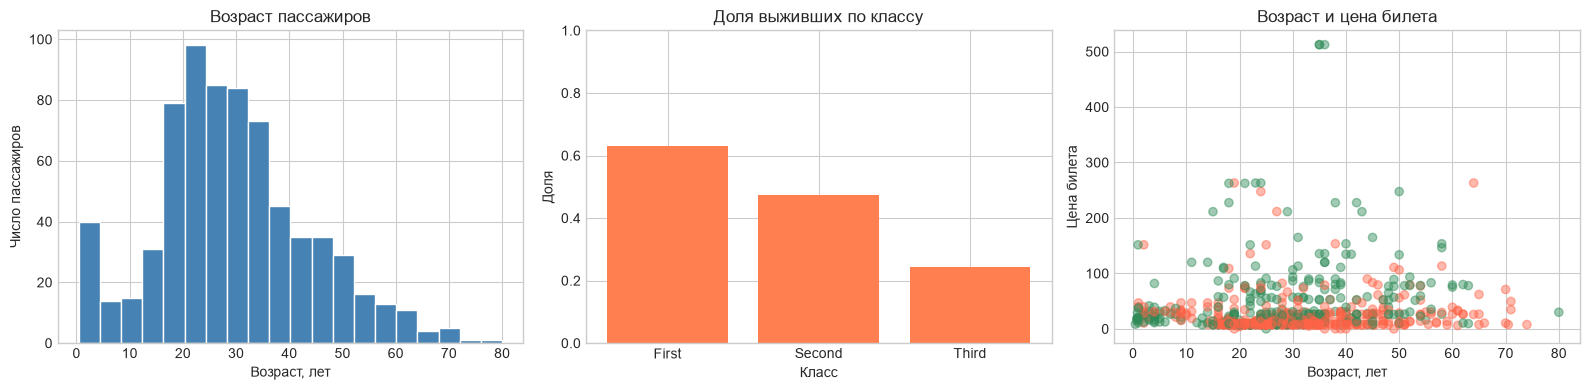

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Распределение числового признака
axes[0].hist(df['age'].dropna(), bins=20, color='steelblue', edgecolor='white')
axes[0].set(title='Возраст пассажиров', xlabel='Возраст, лет', ylabel='Число пассажиров')

# 2. Категории — столбики; среднее 0/1 = доля выживших
rates = df.groupby('class', observed=True)['survived'].mean().reindex(['First', 'Second', 'Third'])
axes[1].bar(rates.index, rates, color='coral')
axes[1].set(title='Доля выживших по классу', xlabel='Класс', ylabel='Доля')
axes[1].set_ylim(0, 1)

# 3. Связь двух чисел; цветом — класс ответа
colors = df['survived'].map({0: 'tomato', 1: 'seagreen'})
axes[2].scatter(df['age'], df['fare'], c=colors, alpha=.45)
axes[2].set(title='Возраст и цена билета', xlabel='Возраст, лет', ylabel='Цена билета')

plt.tight_layout()

### Шпаргалка matplotlib

| Задача | Команда | Пример |
|---|---|---|
| Распределение числа | `ax.hist(x, bins=...)` | возраст |
| Сравнить категории | `ax.bar(names, values)` | доли по классу |
| Связь двух чисел | `ax.scatter(x, y)` | возраст и цена |
| Изменение во времени | `ax.plot(x, y)` | температура по дням |
| Сравнить распределения | `ax.boxplot([...])` | цена в разных классах |
| Несколько графиков | `fig, axes = plt.subplots(...)` | одна фигура, несколько осей |

Как читать строки кода выше: `plt.subplots(1, 3)` создаёт одну фигуру с тремя местами для графиков; `axes[0]` — левое место; `.hist`, `.bar` и `.scatter` рисуют; `.set(...)` подписывает. `alpha=.45` делает точки полупрозрачными: там, где их много, цвет становится плотнее.

Полезные настройки: `ax.set(title='...', xlabel='...', ylabel='...')`, `ax.legend()`, `ax.set_ylim(0, 1)`, `plt.tight_layout()`.

**Разбор графика:** столбцы выше не доказывают, что класс *вызывает* выживание: с ним могут быть связаны пол, место каюты, доступ к шлюпкам и другие факторы. График показывает связь, не причину.

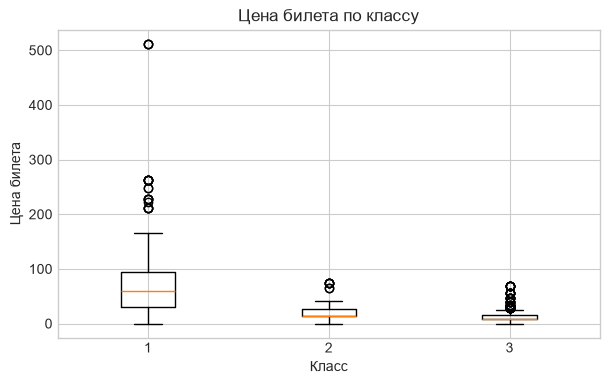

In [6]:
# Попробуйте сами: цена билета часто имеет длинный хвост.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df['pclass'] == c, 'fare'].dropna() for c in [1, 2, 3]], tick_labels=['1', '2', '3'])
ax.set(title='Цена билета по классу', xlabel='Класс', ylabel='Цена билета')
plt.show()

## Мини-учебник по matplotlib: как собрать график с нуля

У matplotlib обычно два объекта: **figure** — весь лист, **axes** (часто сокращают до `ax`) — одно место для графика на листе. Поэтому шаблон почти всегда такой:

```python
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x, y)              # или hist / bar / plot
ax.set(title='...', xlabel='...', ylabel='...')
plt.show()
```

Сначала выберите вопрос, затем тип графика, затем подписи. Не начинайте с цветов. В примерах ниже один и тот же Titanic отвечает на четыре разных вопроса.

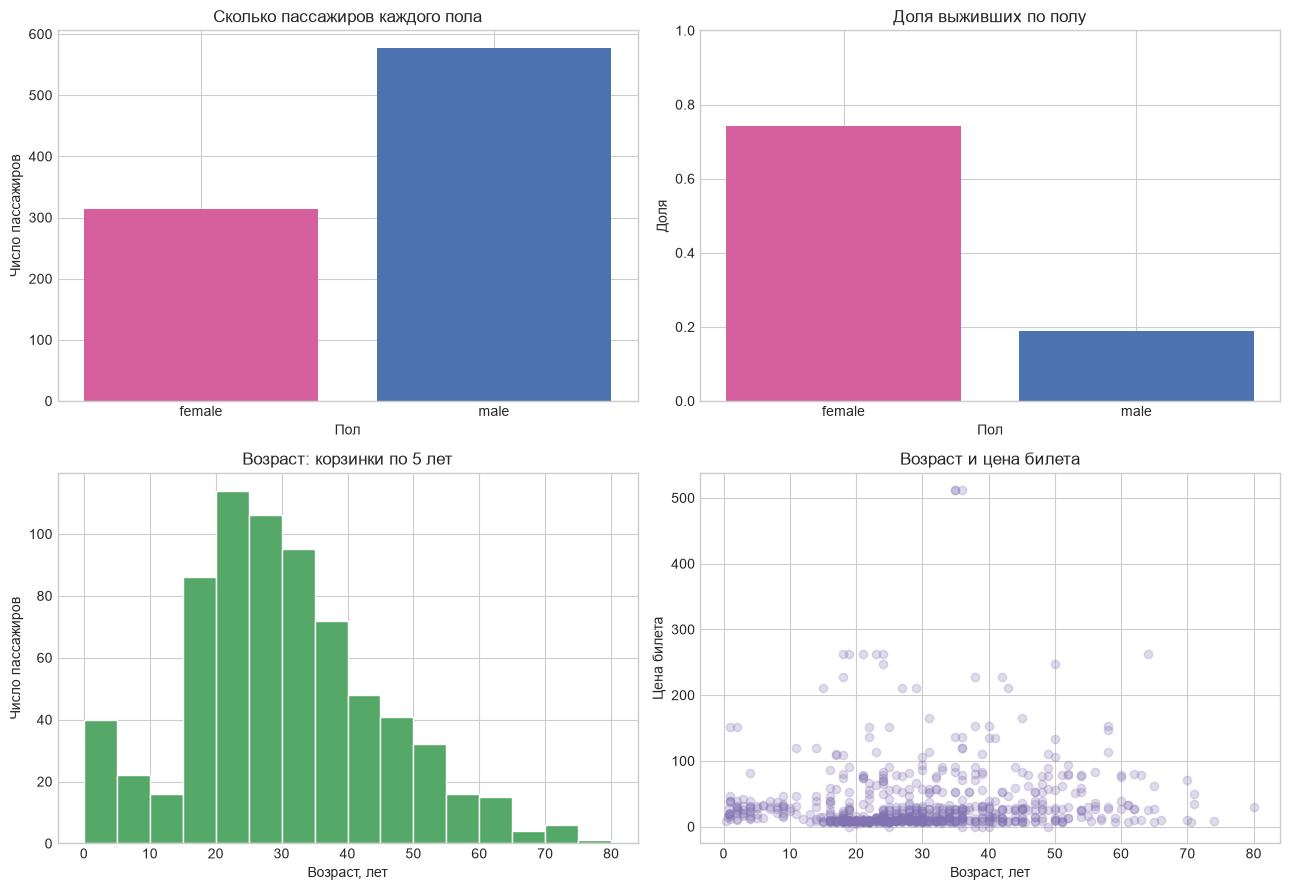

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Сколько пассажиров в каждой категории? Считаем КОЛИЧЕСТВО.
sex_counts = df['sex'].value_counts().reindex(['female', 'male'])
axes[0, 0].bar(sex_counts.index, sex_counts.values, color=['#d65f9e', '#4c72b0'])
axes[0, 0].set(title='Сколько пассажиров каждого пола', xlabel='Пол', ylabel='Число пассажиров')

# 2. Тот же признак, но другой вопрос: теперь ДОЛЯ выживших.
sex_rate = df.groupby('sex')['survived'].mean().reindex(['female', 'male'])
axes[0, 1].bar(sex_rate.index, sex_rate.values, color=['#d65f9e', '#4c72b0'])
axes[0, 1].set(title='Доля выживших по полу', xlabel='Пол', ylabel='Доля', ylim=(0, 1))

# 3. Распределение: где находится большинство возрастов?
axes[1, 0].hist(df['age'].dropna(), bins=np.arange(0, 85, 5), color='#55a868', edgecolor='white')
axes[1, 0].set(title='Возраст: корзинки по 5 лет', xlabel='Возраст, лет', ylabel='Число пассажиров')

# 4. Связь двух чисел: точки, а не линия, потому что порядок строк не время.
axes[1, 1].scatter(df['age'], df['fare'], alpha=.25, color='#8172b2')
axes[1, 1].set(title='Возраст и цена билета', xlabel='Возраст, лет', ylabel='Цена билета')

plt.tight_layout(); plt.show()

### Шпаргалка параметров matplotlib

| Что хотите изменить | Пример | Эффект |
|---|---|---|
| Размер рисунка | `plt.subplots(figsize=(10, 5))` | ширина и высота в дюймах |
| Число корзинок | `ax.hist(x, bins=20)` | больше `bins` — подробнее, но шумнее |
| Прозрачность | `ax.scatter(x, y, alpha=.3)` | видно плотные скопления точек |
| Цвет | `color='crimson'` | один цвет для серии |
| Название серии | `label='модель'`, затем `ax.legend()` | появляется легенда |
| Границы оси | `ax.set_ylim(0, 1)` | удобно для вероятностей и долей |
| Сетка | `ax.grid(alpha=.3)` | облегчает чтение значений |
| Подпись точки | `ax.annotate('выброс', xy=(x, y))` | объясняет важный объект |
| Несколько осей | `fig, axes = plt.subplots(2, 2)` | `axes[строка, столбец]` выбирает место |
| Отступы | `plt.tight_layout()` | подписи не наезжают друг на друга |

Для готового графика всегда спросите себя: что означает высота? число объектов, среднее, доля или вероятность? От ответа зависит подпись Y и вывод.

### Линия нужна не всегда

Линия подразумевает порядок: день 1 → день 2 → день 3. Для случайных строк таблицы соединять точки линией нельзя — получится воображаемый маршрут. Но можно сначала **агрегировать** данные, например посчитать долю выживших в возрастных группах. Тогда порядок возрастных групп осмыслен, и линия становится полезной.

,доля выживших,пассажиров
age_group,,
"[0, 12)",0.573529,68
"[12, 18)",0.488889,45
"[18, 30)",0.350554,271
"[30, 45)",0.423256,215
"[45, 60)",0.404494,89
"[60, 100)",0.269231,26


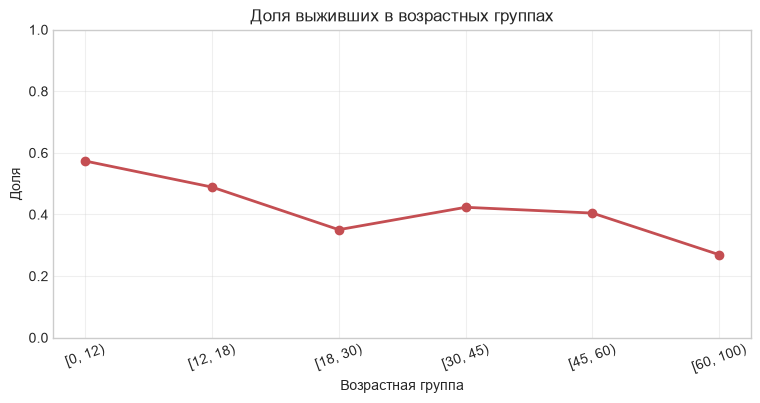

In [8]:
# pd.cut создаёт возрастные интервалы; observed=True не добавляет пустые категории.
age_data = df.dropna(subset=['age']).copy()
age_data['age_group'] = pd.cut(age_data['age'], bins=[0, 12, 18, 30, 45, 60, 100], right=False)
by_age = age_data.groupby('age_group', observed=True)['survived'].agg(['mean', 'count'])
display(by_age.rename(columns={'mean': 'доля выживших', 'count': 'пассажиров'}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_age.index.astype(str), by_age['mean'], marker='o', linewidth=2, color='#c44e52')
ax.set(title='Доля выживших в возрастных группах', xlabel='Возрастная группа', ylabel='Доля', ylim=(0, 1))
ax.grid(alpha=.3); plt.xticks(rotation=20); plt.show()

### Чек-лист честной визуализации

- Укажите, что именно на каждой оси и в каких единицах.
- Не скрывайте размер группы: доля 100% среди 1 человека менее надёжна, чем 60% среди 500.
- Для долей не обрезайте ось Y так, чтобы маленькая разница выглядела огромной.
- Не объявляйте причину по одному графику: «связано с» и «вызывает» — разные вещи.
- Проверяйте выбросы и пропуски: один билет за 512 может растянуть шкалу для всех остальных.
- Под графиком формулируйте вывод полным предложением: «в этой выборке наблюдается…», а не «модель доказала…».

# 2. Что такое обучение с учителем

У нас есть примеры `(X, y)`: характеристики пассажира и известный исход. Алгоритм подбирает правило `f(X)`, чтобы на новых пассажирах его прогноз был близок к `y`. Это называется **обучением с учителем**: учитель — уже известный правильный ответ в старых примерах.

Важно: компьютер не понимает слова «женщина», «опасность» или «справедливость». Он видит числа и ищет повторяющиеся закономерности. Модель не знает будущего, не доказывает причины и может ошибаться на людях, непохожих на обучающую выборку.

Разделение обязательно:

- **train** — строки, на которых модель подбирает параметры;
- **test** — отложенные строки, которых модель не видела; на них мы имитируем будущее.

Представьте подготовку к контрольной: решённые задачи — train, а сама контрольная — test. Если подсматривать ответы контрольной, оценка будет высокой, но знаний не прибавится. Точно так же нельзя оценивать модель на строках, на которых она училась.

В классификации добавляют `stratify=y`, чтобы доля выживших в обеих частях была похожа. Любую обработку, которая что-то *вычисляет* по данным (например, медиану для пропусков), честнее `fit` только на train, а затем применять к test. Иначе test незаметно передаст модели информацию о себе. `random_state=42` фиксирует случайное разбиение: при повторном запуске получится тот же результат.

## Линейная регрессия — прогноз числа

Когда цель — число (цена квартиры, температура, цена билета), линейная регрессия предполагает линию/плоскость:

$$\hat y = w_0 + w_1x_1 + w_2x_2 + \dots + w_px_p.$$

Сначала представьте один признак: например, количество часов подготовки `x` и балл за работу `y`. Модель рисует прямую. Она не обязана пройти через каждую точку: её задача — быть в среднем как можно ближе ко всем точкам.

`w0` — свободный член: прогноз, когда все признаки равны нулю. `w1` — наклон: насколько меняется прогноз, когда `x1` увеличивается на 1, а остальные признаки не меняются. При нескольких признаках это уже не линия на листе, а плоскость или более многомерный аналог.

Обучение ищет такие веса, которые минимизируют среднюю квадратичную ошибку:

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2.$$

Для одного объекта ошибка — `реальный ответ − прогноз`. Возведение в квадрат нужно по двум причинам: ошибки «в плюс» и «в минус» не уничтожают друг друга, а большие промахи становятся особенно заметны.

Линейная регрессия не выдаёт вероятность и не подходит для цели 0/1: она может предсказать −0.2 или 1.3. Поэтому для вопроса «да/нет» мы используем следующую модель.

/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


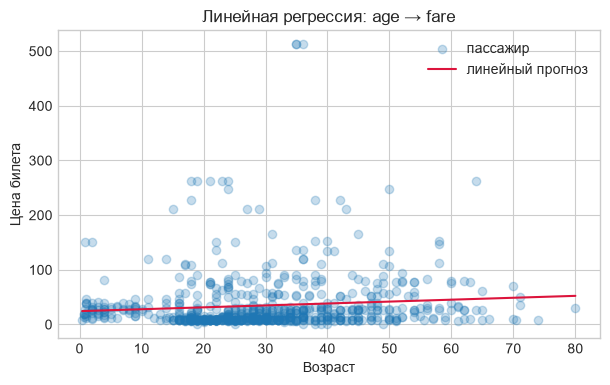

intercept = 24.3 coefficient age = 0.35


In [9]:
# Игрушечный пример: цена билета как функция возраста — связь слабая, но механика видна.
linear_data = df[['age', 'fare']].dropna()
X_linear = linear_data[['age']]
y_linear = linear_data['fare']
line = LinearRegression().fit(X_linear, y_linear)
grid = np.linspace(X_linear['age'].min(), X_linear['age'].max(), 100).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_linear['age'], y_linear, alpha=.25, label='пассажир')
ax.plot(grid, line.predict(grid), color='crimson', label='линейный прогноз')
ax.set(title='Линейная регрессия: age → fare', xlabel='Возраст', ylabel='Цена билета')
ax.legend(); plt.show()
print('intercept =', round(line.intercept_, 2), 'coefficient age =', round(line.coef_[0], 2))

### Линейная регрессия на четырёх точках: что делают `.fit()` и `.predict()`

Ниже `X_toy` — таблица с одним столбцом «часы подготовки». Даже для одного признака scikit-learn ждёт **двумерную** таблицу, поэтому у массива форма `(4, 1)`: 4 строки и 1 столбец. `y_toy` — правильные баллы.

`.fit(X, y)` — этап обучения: найти параметры линии. `.predict(X)` — этап применения: подставить признаки в уже найденную линию. Посмотрите на столбец `ошибка`: он равен `реальный балл − прогноз`.

In [10]:
X_toy = np.array([[1], [2], [3], [4]])   # часы подготовки
y_toy = np.array([48, 59, 69, 82])        # балл
toy_line = LinearRegression().fit(X_toy, y_toy)
toy_prediction = toy_line.predict(X_toy)

print('Формула: балл ≈', round(toy_line.intercept_, 1), '+', round(toy_line.coef_[0], 1), '× часы')
display(pd.DataFrame({
    'часы': X_toy.ravel(), 'реальный балл': y_toy,
    'прогноз модели': toy_prediction.round(1),
    'ошибка': (y_toy - toy_prediction).round(1),
}))
print('Прогноз для 5 часов:', round(toy_line.predict([[5]])[0], 1))

Формула: балл ≈ 36.5 + 11.2 × часы


,часы,реальный балл,прогноз модели,ошибка
0,1,48,47.7,0.3
1,2,59,58.9,0.1
2,3,69,70.1,-1.1
3,4,82,81.3,0.7


Прогноз для 5 часов: 92.5


## Логистическая регрессия — прогноз вероятности класса

Несмотря на название, это классификатор, а не «ещё одна регрессия». Он отвечает на вопросы с классами: выжил/не выжил, спам/не спам, есть болезнь/нет болезни.

Сначала модель, как и линейная регрессия, вычисляет счёт `z = w0 + w1x1 + ...`. Но этот счёт может быть любым числом: −10, 2.7, 100. Затем она пропускает его через сигмоиду:

$$p = \sigma(z) = \frac{1}{1+e^{-z}}.$$

`p` всегда между 0 и 1 — это оценка вероятности класса 1. Если `z=0`, то `p=0.5`; при большом положительном `z` вероятность близка к 1, при большом отрицательном — к 0. По умолчанию `predict` ставит класс 1, если `p ≥ 0.5`, а `predict_proba` возвращает сами вероятности. Порог 0.5 не священный: в задаче, где опасно пропустить болезнь, его могут уменьшить.

Обучение минимизирует **log loss**: уверенный неверный прогноз штрафуется особенно сильно. Сказать «вероятность 99%» и ошибиться хуже, чем честно сказать «55%» и ошибиться.

Коэффициент здесь влияет на *логарифм шансов*, а не на вероятность напрямую. Поэтому новичку безопаснее объяснять модель через `predict_proba` и конкретные примеры, а не пытаться сразу интерпретировать каждый коэффициент.

### Сигмоида руками

В этой ячейке нет обучения — только сама формула. Подставьте в `z_values` свои числа и посмотрите: любое число превращается в значение между 0 и 1. Именно поэтому логистическая регрессия умеет возвращать вероятность, а линейная — нет.

In [11]:
z_values = np.array([-4, -2, 0, 2, 4])
probabilities = 1 / (1 + np.exp(-z_values))
pd.DataFrame({'счёт z': z_values, 'сигмоида σ(z)': probabilities.round(3),
              'класс при пороге 0.5': (probabilities >= 0.5).astype(int)})

,счёт z,сигмоида σ(z),класс при пороге 0.5
0,-4,0.018,0
1,-2,0.119,0
2,0,0.500,1
3,2,0.881,1
4,4,0.982,1


## Дерево решений — последовательность вопросов

Дерево похоже на игру «20 вопросов». В корне оно задаёт вопрос вида «`sex_code ≤ 0.5`?». Если да — идём влево, если нет — вправо. В следующем узле задаётся ещё один вопрос, пока мы не попадём в лист — конечный ответ.

Как дерево выбирает вопрос? Оно перебирает признаки и пороги: «возраст ≤ 18?», «цена ≤ 30?», «класс ≤ 2?». После каждого варианта смотрит, стали ли две получившиеся группы более однородными по ответу. Для классификации чистоту часто измеряют индексом Джини:

$$Gini = 1 - \sum_k p_k^2.$$

Если в узле все выжили, то `p(выжил)=1`, а Gini = 0 — узел чистый. Если половина выжила, половина нет, Gini = `1 − 0.5² − 0.5² = 0.5` — неопределённость максимальна для двух классов. Дерево выбирает вопрос, который сильнее уменьшает такую неопределённость.

Дерево удобно рисовать и объяснять. Но глубокое дерево может запомнить почти каждую строку train: «если возраст 27.5 и цена 13.2, ответ 1». На test оно часто ломается. Это **переобучение**: отличная память вместо полезного правила. Ограничения `max_depth` (сколько вопросов разрешено) и `min_samples_leaf` (сколько объектов должно остаться в листе) помогают обобщать.

## Случайный лес — много разных деревьев

Одно дерево похоже на мнение одного ученика: оно может случайно запомнить неудачные примеры. Случайный лес собирает много деревьев и спрашивает их всех.

Каждое дерево получает случайную выборку строк **с возвращением**: одна строка может попасть несколько раз, а другая не попасть вовсе. Это называется bootstrap. Ещё в каждом узле дерево смотрит не на все признаки, а только на случайную часть. Поэтому деревья получаются разными, а не копиями друг друга.

Для классификации деревья голосуют, а лес усредняет вероятности. Усреднение ошибок многих разных деревьев делает результат стабильнее и обычно снижает переобучение.

Плюсы: это сильная базовая модель для табличных данных, она замечает нелинейные зависимости и не требует приводить признаки к одному масштабу. Минусы: её сложнее объяснять, она работает тяжелее одного дерева, а «важность признака» не доказывает причинность.

Начните настройку с: `n_estimators` — сколько деревьев, `max_depth` — насколько каждое может вырасти, `min_samples_leaf` — насколько крупными должны быть листья. Всегда фиксируйте `random_state`, иначе при каждом запуске случайный лес чуть меняется.

# 2.5. Что происходит внутри модели

Библиотека scikit-learn полезна, но не должна быть чёрным ящиком. В следующих мини-экспериментах мы намеренно используем маленькие искусственные данные. На них можно увидеть весь механизм: модель делает прогноз, измеряет ошибку, слегка меняет свои параметры и повторяет. Реальные данные Titanic будут ниже.

## Внутри линейной регрессии: подбор прямой

У прямой с одним признаком всего два неизвестных: наклон `w` и сдвиг `b`. Прогноз: `ŷ = w × x + b`. Обучить модель — значит подобрать именно эти два числа.

Один распространённый способ — **градиентный спуск**. Алгоритм начинает с плохой догадки, например `w=0`, `b=0`, считает MSE, смотрит, в какую сторону надо сдвинуть параметры, делает небольшой шаг и повторяет сотни раз. Размер шага — `learning_rate`. Слишком большой шаг может перепрыгивать минимум, слишком маленький — учиться очень долго.

Для MSE направления изменения можно вычислить так: `dw = 2/n × Σ(x × (ŷ − y))`, `db = 2/n × Σ(ŷ − y)`. Не обязательно заучивать формулы: важно понимать, что знак ошибки подсказывает, приподнять или опустить линию. В реальном `LinearRegression` scikit-learn использует более быстрый математический способ, но смысл — тот же: найти линию с минимальной MSE.

Найдены параметры: w=2.000, b=1.000; последняя MSE=0.00000000


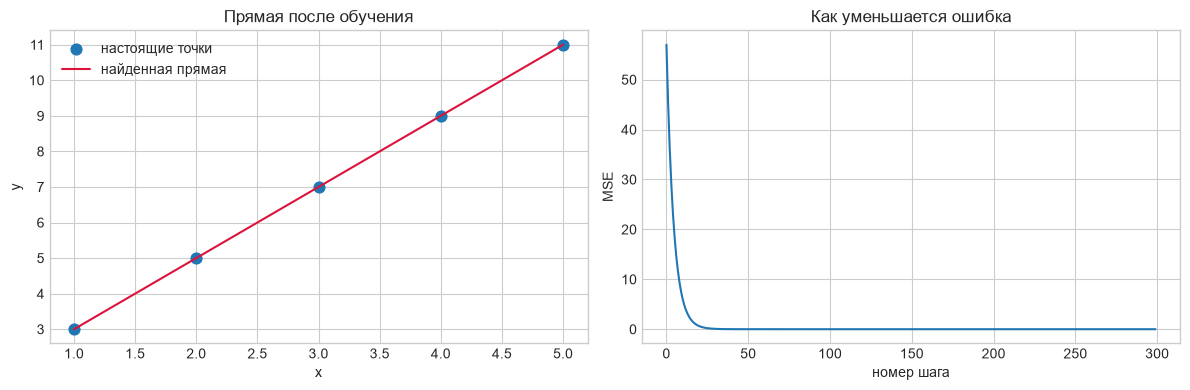

In [12]:
# Линейная регрессия «вручную»: 300 маленьких шагов градиентного спуска.
x_gd = np.array([1., 2., 3., 4., 5.])
y_gd = np.array([3., 5., 7., 9., 11.])  # здесь правильная линия y = 2x + 1
w, b = 0.0, 0.0
learning_rate = 0.08
loss_history = []

for step in range(300):
    prediction = w * x_gd + b
    error = prediction - y_gd
    loss_history.append(np.mean(error ** 2))
    dw = 2 * np.mean(x_gd * error)
    db = 2 * np.mean(error)
    w -= learning_rate * dw
    b -= learning_rate * db

print(f'Найдены параметры: w={w:.3f}, b={b:.3f}; последняя MSE={loss_history[-1]:.8f}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(x_gd, y_gd, s=60, label='настоящие точки')
axes[0].plot(x_gd, w * x_gd + b, color='crimson', label='найденная прямая')
axes[0].set(title='Прямая после обучения', xlabel='x', ylabel='y'); axes[0].legend()
axes[1].plot(loss_history)
axes[1].set(title='Как уменьшается ошибка', xlabel='номер шага', ylabel='MSE')
plt.tight_layout(); plt.show()

### Шпаргалка: линейная регрессия

| Что | Где посмотреть / изменить | Зачем |
|---|---|---|
| Обучить | `model.fit(X_train, y_train)` | подобрать коэффициенты по train |
| Сделать прогноз | `model.predict(X_test)` | получить числа, а не классы |
| Наклоны | `model.coef_` | по одному числу на признак |
| Сдвиг | `model.intercept_` | прогноз при нулевых признаках |
| Ошибка | `mean_squared_error(y, pred)` | средний квадрат промаха; меньше — лучше |
| `fit_intercept` | `LinearRegression(fit_intercept=True)` | обычно оставляют `True`, чтобы модель нашла сдвиг |

Линейная модель хорошо подходит, когда цель — число и связь примерно похожа на прямую. Если график сильно изгибается, есть скачки или важны правила «если… то…», дерево часто окажется естественнее.

## Внутри логистической регрессии: счёт, сигмоида, вероятность

Логистическая регрессия тоже строит линейный счёт `z = w₁x₁ + … + b`, но не называет его ответом. Она превращает его сигмоидой в вероятность. На графике ниже видно S-образную кривую: около нуля она быстро меняется, а у 0 и 1 постепенно «упирается в потолок».

Во время обучения веса подбираются так, чтобы реальные единицы получали высокую вероятность, а реальные нули — низкую. Для этого используется log loss. Модель, которая уверенно ошиблась, получает очень большой штраф. Поэтому оптимизируется не просто количество угаданных классов после порога 0.5, а качество самих вероятностей.

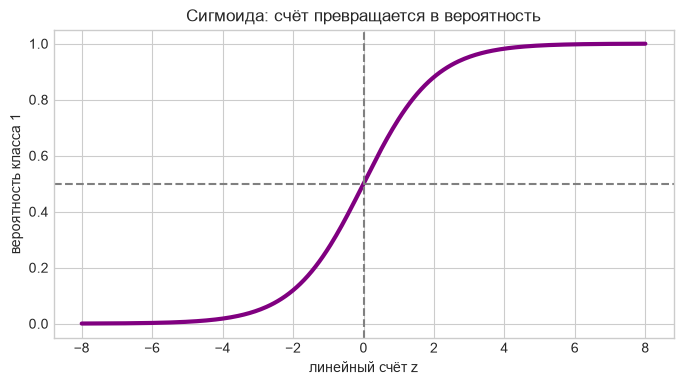

log loss осторожной модели: 0.308
log loss уверенно ошибшейся модели: 2.308


In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_grid = np.linspace(-8, 8, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(z_grid, sigmoid(z_grid), color='purple', linewidth=3)
ax.axhline(0.5, color='gray', linestyle='--'); ax.axvline(0, color='gray', linestyle='--')
ax.set(title='Сигмоида: счёт превращается в вероятность', xlabel='линейный счёт z', ylabel='вероятность класса 1', ylim=(-.05, 1.05))
plt.show()

# Одинаковая accuracy может скрывать разные вероятности.
y_small = np.array([0, 0, 1, 1])
careful = np.array([.10, .40, .60, .90])
overconfident_wrong = np.array([.01, .99, .99, .01])
print('log loss осторожной модели:', round(log_loss(y_small, careful), 3))
print('log loss уверенно ошибшейся модели:', round(log_loss(y_small, overconfident_wrong), 3))

### Шпаргалка: логистическая регрессия

| Параметр / метод | Что означает | Когда менять |
|---|---|---|
| `max_iter=1000` | максимум шагов поиска весов | увеличьте, если появляется предупреждение о сходимости |
| `C=1.0` | насколько модель может делать большие веса; больше `C` — слабее сдерживание | настраивают на валидации, не на test |
| `class_weight='balanced'` | сильнее учитывает редкий класс | при заметном дисбалансе классов |
| `random_state=42` | фиксирует случайность некоторых способов обучения | для повторяемого урока и эксперимента |
| `.predict_proba(X)` | вероятность каждого класса | когда важна уверенность, а не только 0/1 |
| `.predict(X)` | класс после порога | для готового решения «да/нет» |

Признаки с очень разными масштабами (например, возраст 20 и цена 500) логистической регрессии часто полезно стандартизировать. Деревьям это обычно не требуется.

## Внутри дерева: как выбрать первый вопрос

Дерево пробует много возможных вопросов и сравнивает их. Допустим, есть возраст `[8, 14, 30, 40]`. Возможные пороги лежат между значениями: 11, 22, 35. Для каждого порога дерево делит строки на левую и правую части, считает Gini в каждой части и берёт их среднее с весами по размеру частей. Лучший вопрос даёт наименьшую взвешенную нечистоту.

Ниже тот же расчёт виден в числах. Не пугайтесь функции: она просто считает доли классов, а затем формулу `1 − Σ p²`.

In [14]:
tree_toy = pd.DataFrame({
    'age': [8, 14, 30, 40, 45, 50],
    'sex_code': [1, 1, 0, 0, 1, 0],
    'survived': [1, 1, 0, 0, 1, 0],
})

def gini(y):
    probabilities = pd.Series(y).value_counts(normalize=True)
    return 1 - np.sum(probabilities ** 2)

def split_gini(df_part, column, threshold):
    left = df_part.loc[df_part[column] <= threshold, 'survived']
    right = df_part.loc[df_part[column] > threshold, 'survived']
    return (len(left) * gini(left) + len(right) * gini(right)) / len(df_part)

thresholds = [11, 22, 35, 42] 
scores_for_splits = pd.DataFrame({
    'порог возраста': thresholds,
    'взвешенный Gini после разделения': [split_gini(tree_toy, 'age', t) for t in thresholds],
})
display(scores_for_splits.sort_values('взвешенный Gini после разделения'))
print('Gini до первого вопроса:', round(gini(tree_toy['survived']), 3))

,порог возраста,взвешенный Gini после разделения
1,22,0.250000
0,11,0.400000
2,35,0.444444
3,42,0.500000


Gini до первого вопроса: 0.5


### Шпаргалка: дерево решений

| Параметр | За что отвечает | Безопасная отправная точка |
|---|---|---|
| `criterion='gini'` | мера чистоты узлов | оставьте по умолчанию |
| `max_depth` | максимальное число уровней вопросов | 3–8 для первого эксперимента |
| `min_samples_split` | сколько строк нужно, чтобы ещё делить узел | повышайте для менее сложного дерева |
| `min_samples_leaf` | минимум строк в конечном листе | 5–20 для защиты от запоминания |
| `max_features` | сколько признаков пробовать в вопросе | чаще важно в лесу, не в одиночном дереве |
| `random_state` | фиксирует случайность | ставьте 42 в учебных опытах |

Признак переобучения: accuracy на train почти 1.0, а на test заметно хуже. Не лечите это «подглядыванием» в test: уменьшайте глубину, увеличивайте размер листьев или собирайте больше данных.

## Внутри случайного леса: голосование разных деревьев

Лес не строит одно идеальное дерево. Он строит много достаточно хороших и разных деревьев. Разнообразие возникает из двух случайностей: каждое дерево видит свою bootstrap-выборку строк, а каждый вопрос внутри дерева рассматривает лишь часть признаков.

Представьте девять одноклассников, которые видели немного разные примеры и отвечают независимо. Отдельный может ошибиться, но большинство часто устойчивее. Это и есть интуиция голосования. Важное условие — деревья должны быть не одинаковыми, иначе девять раз повторится та же ошибка.

In [15]:
# Как выглядит bootstrap: в выборке из 6 строк некоторые номера повторяются.
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_indices = rng.integers(0, len(tree_toy), size=len(tree_toy))
print('Номера строк одной bootstrap-выборки:', bootstrap_indices)
print('Уникальных строк в ней:', len(np.unique(bootstrap_indices)), 'из', len(tree_toy))

X_tree = tree_toy[['age', 'sex_code']]
y_tree = tree_toy['survived']
tiny_forest = RandomForestClassifier(n_estimators=9, max_depth=2, random_state=RANDOM_STATE).fit(X_tree, y_tree)
new_passenger = pd.DataFrame({'age': [20], 'sex_code': [0]})
votes = [int(estimator.predict(new_passenger)[0]) for estimator in tiny_forest.estimators_]
print('Голоса 9 деревьев:', votes)
print('Доля голосов «выжил»:', round(np.mean(votes), 2))
print('Итог леса:', int(tiny_forest.predict(new_passenger)[0]))

Номера строк одной bootstrap-выборки: [0 4 3 2 2 5]
Уникальных строк в ней: 5 из 6
Голоса 9 деревьев: [0, 1, 1, 1, 0, 0, 0, 1, 0]
Доля голосов «выжил»: 0.44
Итог леса: 0


/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/Users/mkir/.pyenv/versions/3.13.14/lib/python3.13/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier 

### Шпаргалка: случайный лес

| Параметр | Что меняет | Практический смысл |
|---|---|---|
| `n_estimators=200` | число деревьев | больше — стабильнее, но дольше; начните со 100–300 |
| `max_depth` | глубину каждого дерева | ограничьте, если train сильно лучше test |
| `min_samples_leaf` | размер конечного листа | больше — более гладкие, менее шумные правила |
| `max_features` | долю признаков на каждом вопросе | добавляет разнообразие деревьям; `sqrt` — частый выбор для классификации |
| `bootstrap=True` | выборку строк с возвращением | обычно оставляют включённой |
| `n_jobs=-1` | сколько ядер процессора использовать | ускоряет обучение на своём компьютере |
| `class_weight='balanced'` | вес редкого класса | полезно при сильном дисбалансе |
| `random_state=42` | повторяемость случайности | обязательно для сравнения экспериментов |

Лес не обязан побеждать всегда. На маленьком наборе или при очень простом правиле логистическая регрессия или небольшое дерево могут быть не хуже и гораздо понятнее.

# 3. Titanic: честный эксперимент

Сделаем небольшой, воспроизводимый конвейер. Берём признаки, которые известны до исхода: класс, возраст, цена, пол. Не используем `alive`, `who`, `adult_male` — в них уже содержится информация, близкая к результату или производная от пола/возраста.

Разберём следующие строки кода заранее:

1. `.copy()` делает отдельную таблицу. Так мы не испортим исходный `df`.
2. Модели не читают слова `male` и `female`, поэтому создаём понятный числовой столбец `sex_code`: 1 для female и 0 для male. Это называется **кодированием** категории.
3. `X` — четыре входных признака, `y` — один столбец ответов.
4. `train_test_split` прячет 25% строк для честной проверки.
5. В `age` есть пропуски. `SimpleImputer` запоминает медиану только из train (`fit_transform`), а test заполняет этой же сохранённой медианой (`transform`).

Это ещё и повод обсудить справедливость: даже хороший прогноз не означает, что его этично использовать для решения о человеке. Пол и класс билета в учебном историческом наборе помогают увидеть статистическую связь; в реальном приложении использование таких признаков может быть недопустимо и должно проверяться отдельно.

In [16]:
# 1) Подготовка: copy защищает исходный df; медиану считаем только на train ниже.
data = df[['survived', 'pclass', 'sex', 'age', 'fare']].copy()
data['sex_code'] = (data['sex'] == 'female').astype(int)
X = data[['pclass', 'age', 'fare', 'sex_code']]
y = data['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# fit_transform учит медиану на train; transform применяет ту же медиану к test.
imputer = SimpleImputer(strategy='median')
X_train_ready = imputer.fit_transform(X_train)
X_test_ready = imputer.transform(X_test)
print(X_train.shape, X_test.shape, 'доля выживших:', y.mean().round(3))

(668, 4) (223, 4) доля выживших: 0.384


In [17]:
# Базовая линия: всегда отвечать самым частым классом.
baseline = max(y_test.mean(), 1 - y_test.mean())

models = {
    'Логистическая регрессия': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Дерево depth=3': DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE),
    'Случайный лес': RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5, random_state=RANDOM_STATE),
}

fitted = {}
for name, model in models.items():
    fitted[name] = model.fit(X_train_ready, y_train)

scores = pd.Series({name: accuracy_score(y_test, model.predict(X_test_ready)) for name, model in fitted.items()})
print('Базовая линия:', round(baseline, 3))
display(scores.sort_values(ascending=False).rename('accuracy').to_frame())

Базовая линия: 0.614


,accuracy
Дерево depth=3,0.771300
Случайный лес,0.771300
Логистическая регрессия,0.766816


## Как оценивать классификацию

`accuracy` — доля верных ответов: `(число верных прогнозов) / (все прогнозы)`. Она удобна, но опасна при редком классе: если 99% писем не спам, модель «всё не спам» даст 99%. Поэтому всегда сравнивайте с **базовой линией**: насколько точен самый ленивый ответ «всегда самый частый класс».

Одной accuracy недостаточно. Посмотрите на **матрицу ошибок** — таблицу из четырёх видов результата:

- TP: верно нашли класс 1; TN: верно нашли класс 0;
- FP: ложная тревога; FN: пропуск класса 1.

Здесь положительный класс — «выжил».

`precision = TP / (TP + FP)` отвечает «сколько положительных прогнозов верны». Например, если модель сказала «выжил» десять раз, а была права восемь, precision = 0.8. `recall = TP / (TP + FN)` — «какую долю реальных положительных мы нашли». Если выжили десять человек, а модель заметила восемь, recall = 0.8.

Что важнее, зависит от задачи: для болезни страшны FN (пропустить заболевшего), для блокировки хороших писем — FP (ошибочно объявить письмо спамом). Нет одной лучшей метрики для всех задач — сначала нужно понять цену каждой ошибки.

Дерево depth=3
              precision    recall  f1-score   support

    не выжил       0.75      0.93      0.83       137
       выжил       0.83      0.51      0.63        86

    accuracy                           0.77       223
   macro avg       0.79      0.72      0.73       223
weighted avg       0.78      0.77      0.76       223



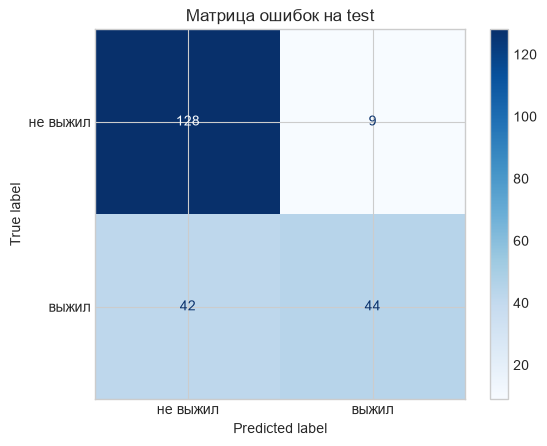

In [18]:
best_name = scores.idxmax()
best = fitted[best_name]
pred = best.predict(X_test_ready)

print(best_name)
print(classification_report(y_test, pred, target_names=['не выжил', 'выжил']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['не выжил', 'выжил']).plot(cmap='Blues')
plt.title('Матрица ошибок на test'); plt.show()

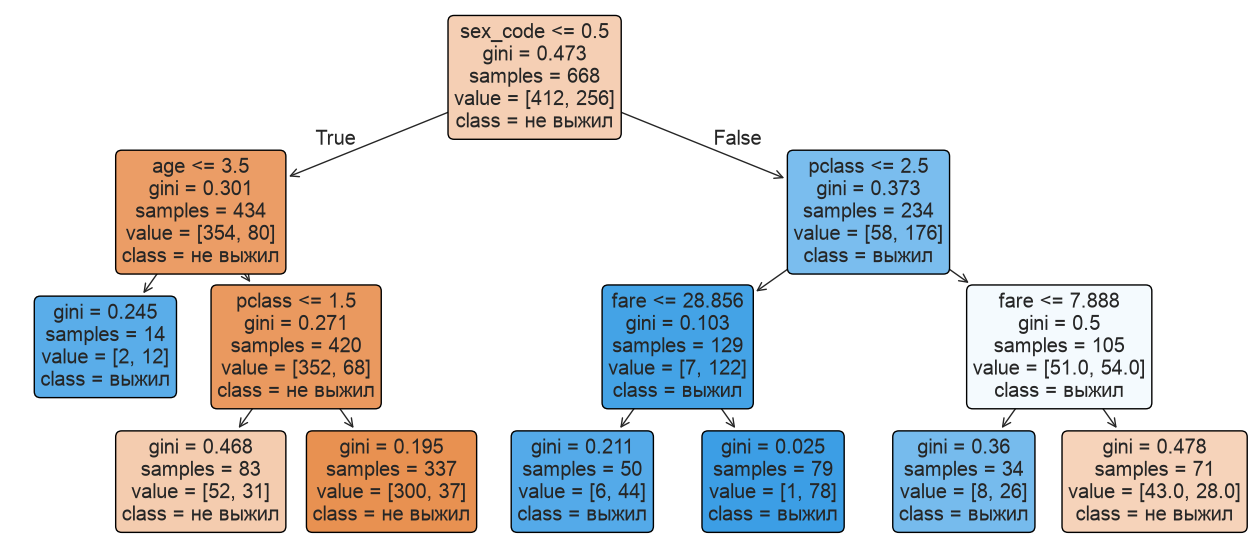

In [19]:
# Умеренно маленькое дерево можно прочитать целиком.
tree = fitted['Дерево depth=3']
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=X.columns, class_names=['не выжил', 'выжил'], filled=True, rounded=True)
plt.show()

## Как пользоваться обученной моделью: полный мини-шаблон

У всех четырёх моделей в scikit-learn похожий интерфейс. Это полезнее запоминать как последовательность действий, а не как набор заклинаний:

```python
model = SomeModel(параметры)      # 1. создать пустую модель
model.fit(X_train, y_train)       # 2. обучить только на train
pred = model.predict(X_test)      # 3. получить прогнозы на новых строках
score = accuracy_score(y_test, pred)  # 4. сравнить с правильными ответами
```

Для классификации добавьте `model.predict_proba(X_test)`: это вероятности. Для регрессии вместо accuracy обычно используют MSE/MAE. Важно: новые данные нужно подготовить **точно так же**, как train: те же столбцы, тот же порядок, те же правила заполнения пропусков и кодирования категорий.

In [20]:
# Один настоящий пассажир из test: модели не видели его при обучении.
one_raw = X_test.iloc[[0]]
one_ready = imputer.transform(one_raw)
one_answer = int(y_test.iloc[0])

print('Признаки пассажира:')
display(one_raw)
for name, model in fitted.items():
    probability = model.predict_proba(one_ready)[0, 1]
    predicted_class = int(model.predict(one_ready)[0])
    print(f'{name}: вероятность выжить = {probability:.1%}; класс = {predicted_class}')
print('Настоящий ответ из test:', one_answer)

Признаки пассажира:


,pclass,age,fare,sex_code
157,3,30.0,8.05,0


Логистическая регрессия: вероятность выжить = 8.8%; класс = 0
Дерево depth=3: вероятность выжить = 11.0%; класс = 0
Случайный лес: вероятность выжить = 12.5%; класс = 0
Настоящий ответ из test: 0


### Как заглянуть внутрь уже обученных моделей

У логистической регрессии коэффициент с плюсом двигает вероятность вверх, с минусом — вниз, **при прочих равных**. Но сравнивать размеры коэффициентов честно только после стандартизации числовых признаков: один шаг по цене (1 фунт) и один шаг по классу (1 класс) имеют разные единицы.

У леса `feature_importances_` показывает, как часто и насколько признаки помогали уменьшать нечистоту в деревьях. Это полезная подсказка, а не доказательство причины и не гарантия, что признак важен для каждого отдельного человека.

In [21]:
feature_names = X.columns
logistic_weights = pd.Series(fitted['Логистическая регрессия'].coef_[0], index=feature_names)
forest_importance = pd.Series(fitted['Случайный лес'].feature_importances_, index=feature_names)
inspection = pd.DataFrame({
    'коэффициент логистической регрессии': logistic_weights,
    'важность в случайном лесе': forest_importance,
}).sort_values('важность в случайном лесе', ascending=False)
display(inspection.round(3))

,коэффициент логистической регрессии,важность в случайном лесе
sex_code,2.513,0.475
fare,0.002,0.236
pclass,-1.107,0.148
age,-0.036,0.141


# 4. Практика: 10 задач

Сначала решите функцию в ячейке, затем запустите тест. Тесты используют маленькие искусственные таблицы: нельзя «подгоняться» под Titanic и нельзя менять входной `DataFrame`. Все функции должны **возвращать** результат, а не печатать его.

Если застряли, используйте один и тот же алгоритм: (1) выпишите вход и ожидаемый выход человеческими словами; (2) сделайте игрушечный пример из 2–3 строк; (3) найдите в документации один нужный метод; (4) проверьте `type(result)` и `result.shape`; (5) только потом запускайте тест. Ошибка — информация о том, какое из предположений не совпало с заданием.

Подсказка по поиску: начинайте с точного названия метода из задания (`pandas fillna median`, `sklearn LogisticRegression fit`). Читайте официальную документацию, проверяйте форму данных через `.shape`, а предположение — на маленьком собственном примере.

In [22]:
from tests_ml_basics import test_task1, test_task2, test_task3, test_task4, test_task5
from tests_ml_basics import test_task6, test_task7, test_task8, test_task9, test_task10

### Задача 1 — стандартизация NumPy (разминка)

`standardize(values)` возвращает новый массив: из каждого числа вычтите среднее массива и разделите на его стандартное отклонение (`np.std`). Например, для `[1, 2, 3]` среднее равно 2: центральный элемент после стандартизации станет 0, левый — отрицательным, правый — положительным. Если все числа одинаковы, верните массив из нулей: на ноль делить нельзя.

**План:** сохраните `mean = np.mean(values)` и `std = np.std(values)`, проверьте `std == 0`, иначе верните `(values - mean) / std`. Полезный поиск: `numpy mean std`.

Проверка: `test_task1(standardize)`

In [23]:
def standardize(values):
    # ваш код
    pass

# test_task1(standardize)

### Задача 2 — выбрать столбцы pandas

`select_columns(df)` возвращает **новый** DataFrame со столбцами `age`, `fare`, `survived` именно в этом порядке. Один квадратный индекс выбирает столбец как Series, два — таблицу: `df[['age', 'fare']]`.

**Подсказка:** передайте список из трёх строковых названий внутрь `df[...]`. Полезный поиск: `pandas select multiple columns`.

Проверка: `test_task2(select_columns)`

In [24]:
def select_columns(df):
    # ваш код
    pass

# test_task2(select_columns)

### Задача 3 — заполнить пропуски

`fill_age(df)` возвращает копию таблицы, где пропуски в `age` заполнены медианой этого столбца. Остальные столбцы не меняются. Исходный `df` трогать нельзя: начните с `result = df.copy()`.

**План:** найдите `result['age'].median()`, затем используйте `.fillna(...)` только для столбца `age`. Полезный поиск: `pandas fillna median copy`.

Проверка: `test_task3(fill_age)`

In [25]:
def fill_age(df):
    # ваш код
    pass

# test_task3(fill_age)

### Задача 4 — закодировать категорию

`encode_sex(df)` возвращает копию с новым столбцом `sex_code`: `female → 1`, `male → 0`. В pandas сравнение целого столбца со строкой создаёт столбец `True/False`; `.astype(int)` превращает `True` в 1, а `False` в 0.

**Подсказка:** после `.copy()` попробуйте выражение `(result['sex'] == 'female').astype(int)`. Полезный поиск: `pandas boolean column astype int`.

Проверка: `test_task4(encode_sex)`

In [ ]:
def encode_sex(df):
    # ваш код
    pass

# test_task4(encode_sex)

### Задача 5 — сформулировать ответ по группам

`survival_rate_by_group(df, group_col)` возвращает Series: среднюю `survived` для каждой категории в `group_col`. Помните: `survived` состоит из нулей и единиц, поэтому среднее — доля выживших.

**Подсказка:** сначала сгруппируйте `df` по имени столбца из переменной `group_col`, затем выберите `survived` и вызовите `.mean()`. Полезный поиск: `pandas groupby column mean`.

Проверка: `test_task5(survival_rate_by_group)`

In [ ]:
def survival_rate_by_group(df, group_col):
    # ваш код
    pass

# test_task5(survival_rate_by_group)

### Задача 6 — собрать матрицу признаков

`make_features(df)` возвращает новый DataFrame со столбцами `pclass`, `age`, `fare`, `sex_code`. Возраст заполните медианой, код пола создайте по правилу выше. Это первый маленький **конвейер признаков**: копия → очистка → новый признак → выбор нужных столбцов.

**Самопроверка:** результат должен иметь ровно четыре столбца и столько же строк, сколько вход. Сначала можно вызвать свои идеи из задач 3–4, но не изменяйте исходную таблицу.

Проверка: `test_task6(make_features)`

In [ ]:
def make_features(df):
    # ваш код
    pass

# test_task6(make_features)

### Задача 7 — обучить линейную регрессию

`fit_linear(X, y)` создаёт `LinearRegression`, обучает методом `.fit(X, y)` и возвращает модель. Это две отдельные строки: сначала `model = LinearRegression()`, затем `model.fit(X, y)`. У `fit` результатом обучения является эта же модель, но возвращайте именно переменную `model`: так проще читать код.

**Подсказка:** аргументы уже готовы: `X` — таблица признаков (или двумерный массив), `y` — ответы. Не вызывайте `predict` в этой задаче. Полезный поиск: `sklearn LinearRegression fit`.

Проверка: `test_task7(fit_linear)`

In [ ]:
def fit_linear(X, y):
    # ваш код
    pass

# test_task7(fit_linear)

### Задача 8 — обучить логистическую регрессию

`fit_logistic(X, y)` возвращает обученный `LogisticRegression`. Укажите `max_iter=1000`, чтобы оптимизация успела сойтись. `max_iter` — запас по числу шагов поиска коэффициентов; это не «точность 1000».

**Подсказка:** структура решения почти такая же, как у линейной регрессии, меняется только класс модели и параметр конструктора. После теста можете самостоятельно вызвать у модели `predict_proba(X[:3])`. Полезный поиск: `sklearn LogisticRegression max_iter fit`.

Проверка: `test_task8(fit_logistic)`

In [ ]:
def fit_logistic(X, y):
    # ваш код
    pass

# test_task8(fit_logistic)

### Задача 9 — небольшое дерево

`fit_tree(X, y)` возвращает обученный `DecisionTreeClassifier(max_depth=2, random_state=42)`. Почему мы ограничиваем глубину? Ответьте одной фразой в Markdown рядом с решением.

**Подсказка:** `max_depth=2` означает не более двух уровней вопросов после корня. Небольшая глубина не даёт дереву запомнить каждую строчку train. Полезный поиск: `sklearn DecisionTreeClassifier max_depth`.

Проверка: `test_task9(fit_tree)`

In [ ]:
def fit_tree(X, y):
    # ваш код
    pass

# test_task9(fit_tree)

### Задача 10 — случайный лес и собственный вывод

`fit_forest(X, y)` возвращает обученный `RandomForestClassifier` с `n_estimators` не меньше 50 и `random_state=42`. `n_estimators=100` — хороший старт: это число деревьев, а не число признаков.

Затем примените его к Titanic: сравните test accuracy с деревом и напишите 3–5 предложений: какая модель победила, достаточно ли одной accuracy и какой признак может быть сомнительным с точки зрения справедливости. Правильный вывод может быть «на этом разбиении результаты почти одинаковы» — не нужно придумывать драму из сотых долей.

**Подсказка:** после создания леса, как и раньше, вызовите `.fit(X, y)` и верните модель. Полезный поиск: `sklearn RandomForestClassifier n_estimators random_state`.

Проверка: `test_task10(fit_forest)`

In [ ]:
def fit_forest(X, y):
    # ваш код
    pass

# test_task10(fit_forest)

# 5. Что проверить перед сдачей

- [ ] Я отделил целевую переменную от признаков и не использовал столбцы, которые знают ответ.
- [ ] Я посмотрел на типы, пропуски, распределения и группы до обучения.
- [ ] Я разделил данные на train/test до оценки качества.
- [ ] Я сравнил модель с базовой линией.
- [ ] Я посмотрел не только на accuracy, но и на ошибки разных типов.
- [ ] Я могу объяснить хотя бы один график и одно ограничение моего вывода.

**Куда расти дальше:** кросс-валидация, `Pipeline` и `ColumnTransformer`, one-hot encoding для категорий с несколькими значениями, ROC-AUC / PR-AUC, настройка гиперпараметров и анализ ошибок.